In [1]:
import lightgbm as lgb
import numpy as np
import pandas as pd

import scripts.feature_engineering as feature
from scripts.evaluate import calculate_metrics

In [2]:
df = pd.read_csv('data/gold/train.csv')
df_cat = pd.read_csv('data/landing/item_categories.csv')
df_items = pd.read_csv('data/landing/items.csv')
df_shops = pd.read_csv('data/landing/shops.csv')
df_sales = pd.read_csv('data/landing/sales_train.csv')

df = feature.add_categories(df, df_cat, df_items)
df = feature.add_cities(df, df_shops)
df = feature.add_target_lags(df, (1, 2, 3, 4, 5, 6, 12))
df = feature.add_lag_stats(df)
df = feature.add_mean_lags(df)
df = feature.add_age_features(df)
df = feature.add_price_features(df, df_sales, df_items)
df = feature.add_calendar(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10884554 entries, 0 to 10884553
Data columns (total 34 columns):
 #   Column                Dtype  
---  ------                -----  
 0   date_block_num        int64  
 1   shop_id               int64  
 2   item_id               int64  
 3   target                float64
 4   item_category_id      uint8  
 5   category_type_id      uint8  
 6   item_type_id          uint8  
 7   city_id               uint8  
 8   target_lag_1          float32
 9   target_lag_2          float32
 10  target_lag_3          float32
 11  target_lag_4          float32
 12  target_lag_5          float32
 13  target_lag_6          float32
 14  target_lag_12         float32
 15  roll3                 float32
 16  roll6                 float32
 17  diff_1_2              float32
 18  item_mean_lag_1       float32
 19  shop_mean_lag_1       float32
 20  cat_mean_lag_1        float32
 21  shop_cat_mean_lag_1   float32
 22  city_item_mean_lag_1  float32
 23  pair_age        

In [3]:
df.tail()

,date_block_num,shop_id,item_id,target,item_category_id,category_type_id,item_type_id,city_id,target_lag_1,target_lag_2,...,pair_since_last,item_age,item_is_new,item_price_last,item_price_ratio,price_rel_cat,month,month_sin,month_cos,days
10884549,33,59,22162,0.0,40,12,7,29,0.0,1.0,...,2.0,15,0,349.0,1.057576,1.249241,10,-1.0,-1.836970e-16,31
10884550,33,59,22163,0.0,40,12,7,29,0.0,0.0,...,NaN,2,0,169.0,1.000000,0.604934,10,-1.0,-1.836970e-16,31
10884551,33,59,22164,0.0,37,12,2,29,0.0,0.0,...,3.0,8,0,549.0,0.785408,1.241430,10,-1.0,-1.836970e-16,31
10884552,33,59,22166,0.0,54,13,60,29,0.0,0.0,...,NaN,24,0,150.0,1.000000,0.656144,10,-1.0,-1.836970e-16,31
10884553,33,59,22167,0.0,49,13,39,29,0.0,0.0,...,16.0,25,0,299.0,1.000000,0.637012,10,-1.0,-1.836970e-16,31


In [4]:
CAT_FEATURES = ['shop_id', 'item_category_id', 'category_type_id', 'item_type_id', 'city_id']
FEATURES = [c for c in df.columns if c not in ('target', 'ID', 'date_block_num', 'item_id')]
print(FEATURES)

['shop_id', 'item_category_id', 'category_type_id', 'item_type_id', 'city_id', 'target_lag_1', 'target_lag_2', 'target_lag_3', 'target_lag_4', 'target_lag_5', 'target_lag_6', 'target_lag_12', 'roll3', 'roll6', 'diff_1_2', 'item_mean_lag_1', 'shop_mean_lag_1', 'cat_mean_lag_1', 'shop_cat_mean_lag_1', 'city_item_mean_lag_1', 'pair_age', 'pair_since_last', 'item_age', 'item_is_new', 'item_price_last', 'item_price_ratio', 'price_rel_cat', 'month', 'month_sin', 'month_cos', 'days']


In [5]:
m = df['date_block_num']
train, valid = df[(m >= 12) & (m <= 31)], df[m == 32]
tr_s = train
tr_s.head()

,date_block_num,shop_id,item_id,target,item_category_id,category_type_id,item_type_id,city_id,target_lag_1,target_lag_2,...,pair_since_last,item_age,item_is_new,item_price_last,item_price_ratio,price_rel_cat,month,month_sin,month_cos,days
4478890,12,2,27,0.0,19,6,13,1,0.0,0.0,...,12.0,12,0,998.0,0.648480,0.608176,1,0.0,1.0,31
4478891,12,2,30,0.0,40,12,7,1,0.0,0.0,...,7.0,11,0,169.0,0.502568,0.655601,1,0.0,1.0,31
4478892,12,2,31,0.0,37,12,2,1,0.0,0.0,...,9.0,11,0,499.0,0.774298,1.202210,1,0.0,1.0,31
4478893,12,2,32,1.0,40,12,7,1,0.0,0.0,...,NaN,12,0,149.0,0.498328,0.578015,1,0.0,1.0,31
4478894,12,2,33,1.0,37,12,2,1,1.0,2.0,...,1.0,12,0,199.0,0.614198,0.479439,1,0.0,1.0,31


In [6]:
model = lgb.LGBMRegressor(
    objective='regression', metric='rmse',
    n_estimators=215, learning_rate=0.05,
    num_leaves=84, min_child_samples=236,
    colsample_bytree=0.6645097995051339, subsample=0.5756895436932168, subsample_freq=1,
    reg_lambda=2.8570139411689,
    random_state=42, n_jobs=-1, verbose=-1,
    cat_smooth=5.178938561126461
)
model.fit(
    train[FEATURES], train['target'],
    eval_X=(tr_s[FEATURES], valid[FEATURES]),
    eval_y=(tr_s['target'], valid['target']),
    eval_names=['train', 'valid'],
    categorical_feature=CAT_FEATURES,
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(50)],
)
print('best_iteration:', model.best_iteration_)

Training until validation scores don't improve for 100 rounds
[50]	train's rmse: 0.819288	valid's rmse: 0.858558
[100]	train's rmse: 0.793052	valid's rmse: 0.851909
[150]	train's rmse: 0.781264	valid's rmse: 0.850537
[200]	train's rmse: 0.773028	valid's rmse: 0.85062
Did not meet early stopping. Best iteration is:
[215]	train's rmse: 0.771	valid's rmse: 0.85042
best_iteration: 215


In [7]:
res = calculate_metrics(
    model,
    {'train': (train[FEATURES], train['target']), 'valid': (valid[FEATURES], valid['target'])},
    model_name='LightGBM',
    baselines={'zeros': np.zeros(len(valid)), 'naive': valid['target_lag_1'].fillna(0)},
    backend='plotly',
)
res.round(4)

,rmse,mae,bias,r2,rmse_nonzero
train,0.7789,0.2908,-0.0003,0.5764,1.8770
valid,0.8504,0.3027,0.0172,0.4693,2.0549
valid: zeros,1.1982,0.2701,-0.2701,-0.0536,3.2177
valid: naive,1.0766,0.3202,0.0106,0.1494,2.6185


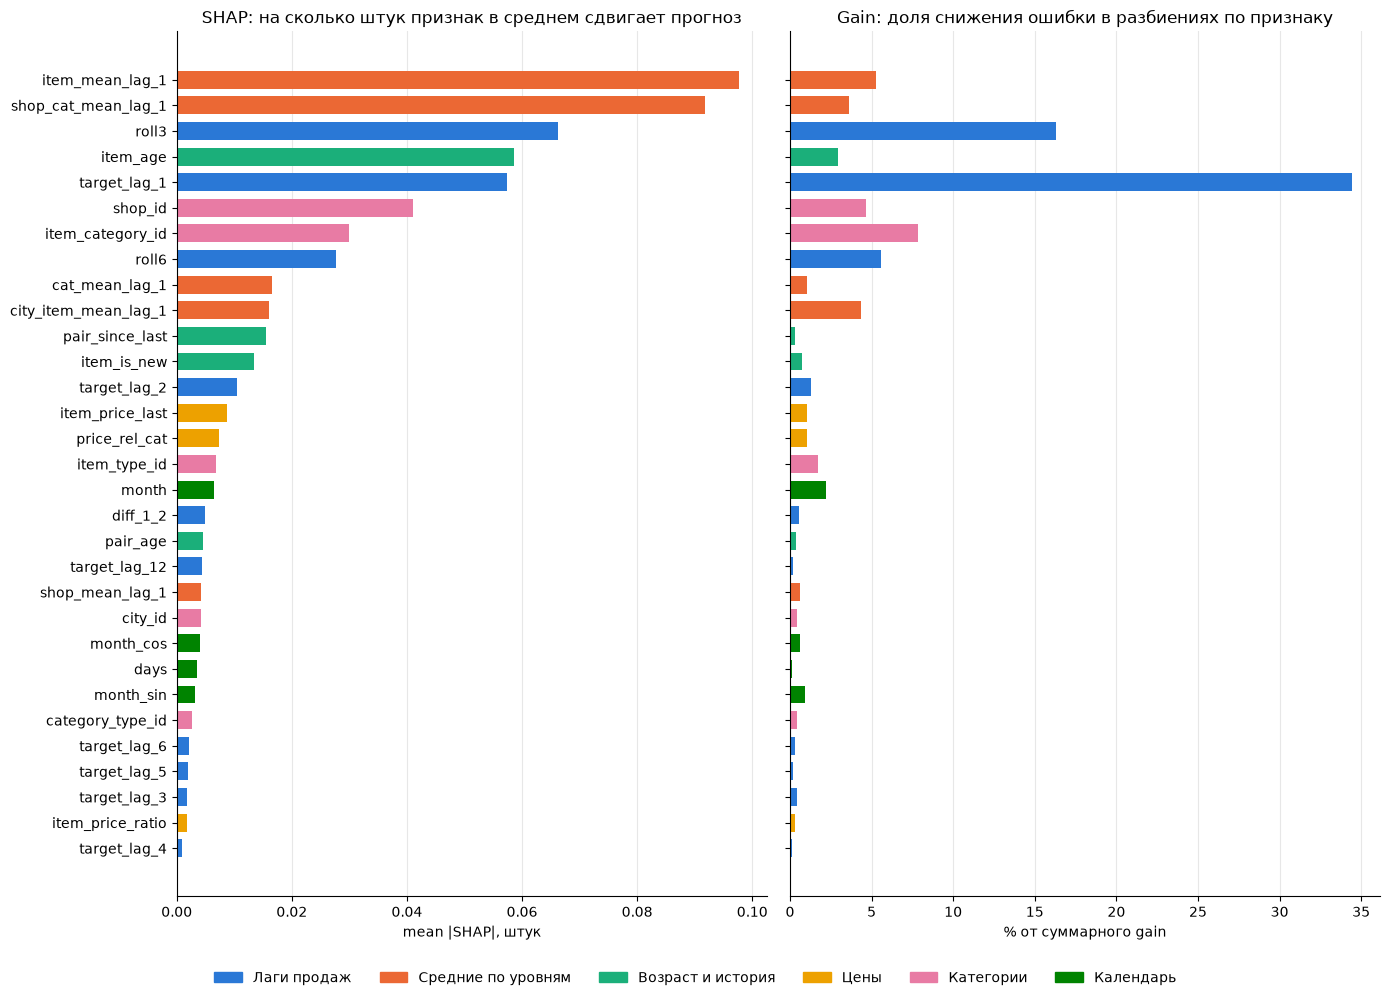

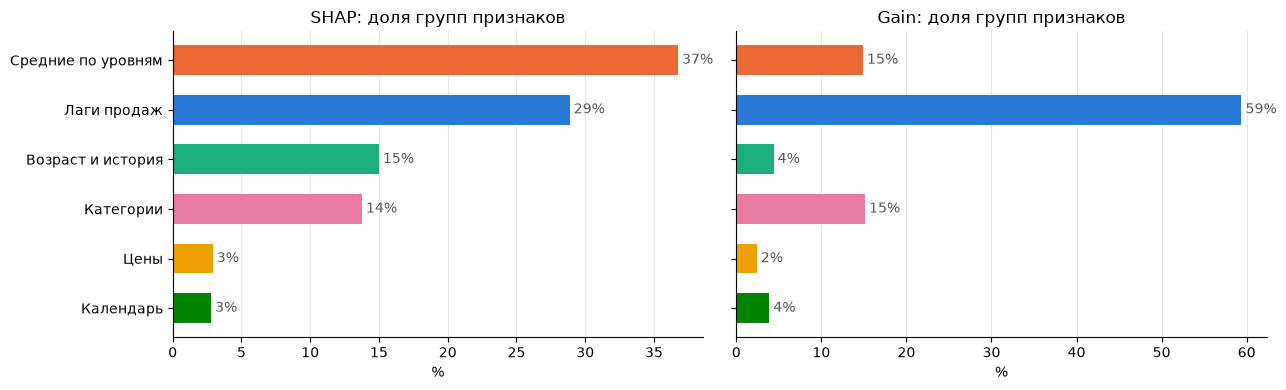

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

GROUP_COLORS = {
    'Лаги продаж': '#2a78d6',
    'Средние по уровням': '#eb6834',
    'Возраст и история': '#1baf7a',
    'Цены': '#eda100',
    'Категории': '#e87ba4',
    'Календарь': '#008300',
}


def feature_group(f: str) -> str:
    if f in CAT_FEATURES:
        return 'Категории'
    if f.startswith('target_lag') or f in ('roll3', 'roll6', 'diff_1_2'):
        return 'Лаги продаж'
    if f.endswith('_mean_lag_1'):
        return 'Средние по уровням'
    if f in ('pair_age', 'pair_since_last', 'item_age', 'item_is_new'):
        return 'Возраст и история'
    if 'price' in f:
        return 'Цены'
    return 'Календарь'


# SHAP встроен в LightGBM: pred_contrib=True раскладывает каждый прогноз на вклады признаков
# (последний столбец - базовое значение). Считаем на valid: важность там, где модель проверяется.
sample = valid.sample(min(100_000, len(valid)), random_state=42)
contrib = model.predict(sample[FEATURES], pred_contrib=True)
imp = pd.DataFrame({
    'shap': np.abs(contrib[:, :-1]).mean(axis=0),
    'gain_pct': 100 * model.booster_.feature_importance('gain') / model.booster_.feature_importance('gain').sum(),
}, index=FEATURES)
imp['group'] = imp.index.map(feature_group)
imp = imp.sort_values('shap')
colors = imp['group'].map(GROUP_COLORS)
legend = [Patch(color=c, label=g) for g, c in GROUP_COLORS.items()]


def _style(ax: plt.Axes) -> None:
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


# 1. По признакам: слева SHAP (в штуках), справа gain (в %), порядок общий - видно, где методы расходятся
fig, axes = plt.subplots(1, 2, figsize=(14, 10), sharey=True)
axes[0].barh(imp.index, imp['shap'], color=colors, height=0.7)
axes[0].set(title='SHAP: на сколько штук признак в среднем сдвигает прогноз', xlabel='mean |SHAP|, штук')
axes[1].barh(imp.index, imp['gain_pct'], color=colors, height=0.7)
axes[1].set(title='Gain: доля снижения ошибки в разбиениях по признаку', xlabel='% от суммарного gain')
for ax in axes:
    _style(ax)
fig.legend(handles=legend, loc='lower center', ncol=len(legend), frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

# 2. По группам: какой тип признаков что даёт модели
grp = imp.groupby('group')[['shap', 'gain_pct']].sum()
grp['shap_pct'] = 100 * grp['shap'] / grp['shap'].sum()
grp = grp.sort_values('shap_pct')
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, col, title in zip(axes, ['shap_pct', 'gain_pct'], ['SHAP', 'Gain']):
    bars = ax.barh(grp.index, grp[col], color=grp.index.map(GROUP_COLORS), height=0.6)
    ax.bar_label(bars, fmt='%.0f%%', padding=3, color='#555555')
    ax.set(title=f'{title}: доля групп признаков', xlabel='%')
    _style(ax)
fig.tight_layout()
plt.show()